<a href="https://colab.research.google.com/github/khalilullahalfaath/credit-scoring-fairness-audit/blob/main/notebooks/eda_train.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# EDA on the training part

`eda.ipynb` audited the data quality of the whole `train.csv`. This notebook applies the cleaning rules, removes customers under 18, splits off a held-out part by `Customer_ID`, and then analyses the **training part only**: distributions and outliers, associations between variables, and the relation of each feature to the target. The held-out part is not read again here.

In [1]:
import sys
if "google.colab" in sys.modules:
    !git clone -q https://github.com/khalilullahalfaath/credit-scoring-fairness-audit.git
    %cd credit-scoring-fairness-audit/notebooks
    !pip install -q -r ../requirements.txt
    !mkdir -p ../data/raw
    from google.colab import drive
    drive.mount('/content/drive')
    !cp "/content/drive/MyDrive/Projects/fairness-credit-scoring/"*.csv ../data/raw/
sys.path.insert(0, "../src")

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy.stats import chi2_contingency, spearmanr
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import GroupKFold

from cleaning import LOAN_COLUMNS, MONTHS, clean_rows, drop_minors, recover_by_customer
from split import holdout_customers

# Chart style: light surface, thin recessive grid, one colour per credit class in every chart
SURFACE, INK, INK2, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9"
BLUE = "#2a78d6"
CLASSES = ["Good", "Standard", "Poor"]
CLASS_COLOR = {"Good": "#2a78d6", "Standard": "#1baf7a", "Poor": "#eb6834"}
DIVERGING = LinearSegmentedColormap.from_list("blue_gray_red", ["#2a78d6", "#f0efec", "#e34948"])
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "axes.titlecolor": INK, "axes.titlesize": 11,
    "axes.titleweight": "regular", "axes.titlelocation": "left", "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.axisbelow": True, "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK,
    "font.size": 9, "figure.dpi": 110, "legend.frameon": False,
})

## 1. Cleaning and split

In [3]:
raw = pd.read_csv("../data/raw/train.csv", low_memory=False)
kept = drop_minors(raw)                                  # customers ever under 18 are removed
df = recover_by_customer(clean_rows(kept))               # layer 1, then layer 2
df["default_risk"] = (df["Credit_Score"] == "Poor").astype(int)

holdout = holdout_customers(df)                          # frozen ids, stratified on default_risk, never splits a customer
is_holdout = df["Customer_ID"].isin(holdout)

cust_age = df.groupby("Customer_ID")["Age"].transform("median")
df["age_group"] = pd.cut(cust_age, [17, 25, 35, 45, 100], labels=["18-25", "26-35", "36-45", "46+"])

def part(d):
    c = d.groupby("Customer_ID").first()
    return {"customers": len(c), "rows": len(d), "default rate": d["default_risk"].mean(),
            "share of customers aged 46+": (c["age_group"] == "46+").mean()}

print(pd.DataFrame({"training": part(df[~is_holdout]), "held-out": part(df[is_holdout])}).round(3).to_string())

train = df[~is_holdout].reset_index(drop=True)
train_raw = kept[~kept["Customer_ID"].isin(holdout)]
del df                                                   # the held-out rows are not used again in this notebook

                              training   held-out
customers                     9369.000   2343.000
rows                         74952.000  18744.000
default rate                     0.279      0.279
share of customers aged 46+      0.154      0.151


In [4]:
assert not train["Customer_ID"].isin(holdout).any()
assert (train.groupby("Customer_ID").size() == 8).all()
offset = (train["Credit_History_Age"] - train["month_idx"]).groupby(train["Customer_ID"]).nunique()
assert (offset == 1).all()                                                       # history grows one month per month
assert (train.groupby("Customer_ID")[["Annual_Income", "Interest_Rate"]].nunique() == 1).all().all()
print("Missing values left after layer 2:", train.isna().sum()[lambda s: s > 0].to_dict())

Missing values left after layer 2: {'Name': 7506}


The split is by customer: 9,369 customers (74,952 rows) for training and 2,343 customers (18,744 rows) held out, with the same default rate in both parts (0.279) and a similar share of customers aged 46+ (15.4% and 15.1%). Removing customers under 18 first lowers the default rate from 0.29 to 0.28. After layer 2 only `Name` has missing values, and the invariants found in the audit hold on this part (8 rows per customer, `Credit_History_Age` growing one month per month, `Annual_Income` and `Interest_Rate` constant per customer). The ids of the held-out customers are saved in `data/processed/` (git-ignored), so the split is computed once per machine.

In [5]:
NUMERIC = ["Annual_Income", "Monthly_Inhand_Salary", "Num_Bank_Accounts", "Num_Credit_Card", "Interest_Rate",
           "Num_of_Loan", "Delay_from_due_date", "Num_of_Delayed_Payment", "Changed_Credit_Limit",
           "Num_Credit_Inquiries", "Outstanding_Debt", "Credit_Utilization_Ratio", "Credit_History_Age",
           "Total_EMI_per_month", "Amount_invested_monthly", "Monthly_Balance"]   # Age is kept out: audit only
CATEGORICAL = ["Occupation", "Credit_Mix", "Payment_of_Min_Amount", "Payment_Behaviour"]
overall = train["default_risk"].mean()

## 2. Target

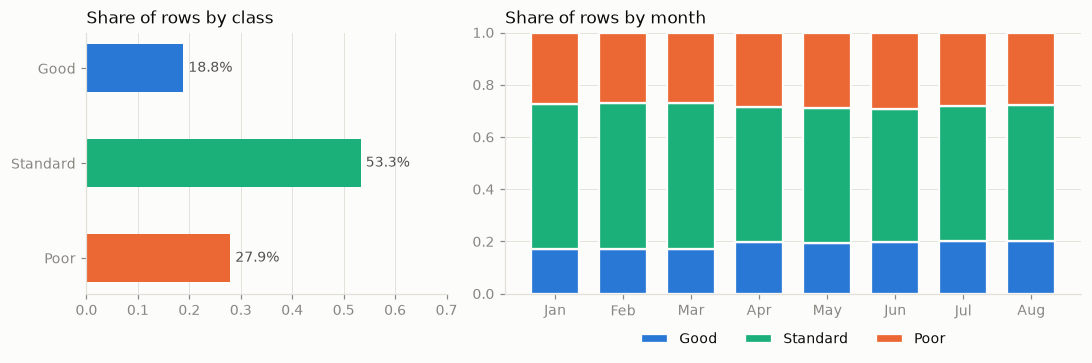

default_risk (Poor) base rate in the training part: 0.279
Credit_Score  Good  Standard  Poor
Month                             
January       17.0      55.8  27.3
February      17.3      55.8  27.0
March         17.0      56.1  26.8
April         19.7      51.7  28.6
May           19.4      51.9  28.8
June          19.8      51.1  29.1
July          20.1      51.9  28.0
August        20.1      52.0  27.8


In [6]:
share = train["Credit_Score"].value_counts(normalize=True).reindex(CLASSES)
by_month = train.groupby("Month")["Credit_Score"].value_counts(normalize=True).unstack()[CLASSES].reindex(MONTHS)

fig, (a, b) = plt.subplots(1, 2, figsize=(10, 3.4), gridspec_kw={"width_ratios": [1, 1.6]})
a.barh(CLASSES, share.values, color=[CLASS_COLOR[c] for c in CLASSES], height=0.5)
for i, v in enumerate(share.values):
    a.text(v + 0.01, i, f"{v:.1%}", va="center", color=INK2)
a.set(xlim=(0, 0.7), title="Share of rows by class")
a.invert_yaxis(); a.grid(axis="y", visible=False)

left = np.zeros(len(by_month))
for c in CLASSES:
    b.bar([m[:3] for m in by_month.index], by_month[c], bottom=left, color=CLASS_COLOR[c],
          edgecolor=SURFACE, linewidth=1.5, label=c, width=0.7)
    left += by_month[c].values
b.set(title="Share of rows by month", ylim=(0, 1))
b.grid(axis="x", visible=False)
b.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.1))
plt.tight_layout(); plt.show()
print(f"default_risk (Poor) base rate in the training part: {overall:.3f}")
print((by_month * 100).round(1).to_string())

The classes are not balanced: `Standard` 53.3%, `Poor` 27.9% and `Good` 18.8%. The mix shifts between March and April: `Good` goes from about 17% to about 20% of the rows and `Standard` from about 56% to about 52%, then stays there, while `Poor` varies between 26.8% and 29.1%. It is a step, not a trend. `Month` is only weakly related to the class (Cramer's V 0.03, section 6), and whether it becomes a feature is not decided.

## 3. Default rate by group (recomputed on the training part)

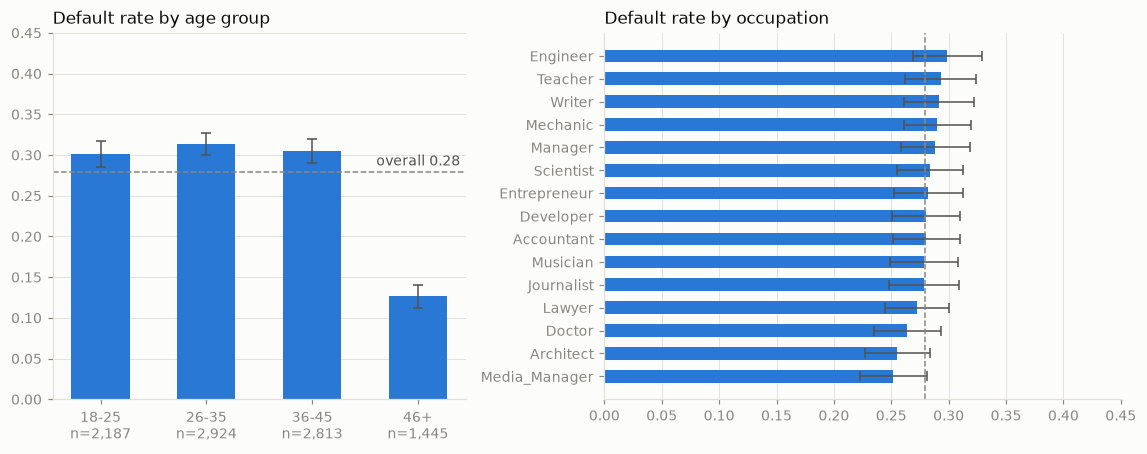

        mean    std  customers   ci95
group                                
18-25  0.301  0.383       2187  0.016
26-35  0.314  0.388       2924  0.014
36-45  0.305  0.386       2813  0.014
46+    0.126  0.273       1445  0.014
                mean    std  customers   ci95
group                                        
Media_Manager  0.252  0.373        633  0.029
Architect      0.255  0.366        637  0.028
Doctor         0.264  0.371        615  0.029
Lawyer         0.273  0.367        665  0.028
Journalist     0.279  0.381        609  0.030
Musician       0.279  0.374        606  0.030
Accountant     0.280  0.376        634  0.029
Developer      0.280  0.383        633  0.030
Entrepreneur   0.282  0.381        623  0.030
Scientist      0.284  0.374        638  0.029
Manager        0.288  0.375        603  0.030
Mechanic       0.290  0.379        647  0.029
Writer         0.292  0.377        593  0.030
Teacher        0.293  0.383        595  0.031
Engineer       0.299  0.388        6

In [7]:
def rate_table(col):
    cust = train.groupby("Customer_ID").agg(group=(col, "first"), rate=("default_risk", "mean"))
    t = cust.groupby("group", observed=True)["rate"].agg(["mean", "std", "size"])
    t["ci95"] = 1.96 * t["std"] / np.sqrt(t["size"])         # customer-level, since the 8 rows of a customer are correlated
    return t.rename(columns={"size": "customers"})

age_t = rate_table("age_group")
occ_t = rate_table("Occupation").sort_values("mean")

fig, (a, b) = plt.subplots(1, 2, figsize=(10.5, 4.2), gridspec_kw={"width_ratios": [1, 1.25]})
err = {"lw": 1, "ecolor": INK2, "capsize": 3}
a.bar([f"{g}\nn={n:,}" for g, n in zip(age_t.index, age_t["customers"])], age_t["mean"],
      yerr=age_t["ci95"], color=BLUE, width=0.55, error_kw=err)
a.axhline(overall, color=MUTED, ls="--", lw=1)
a.text(3.4, overall + 0.008, f"overall {overall:.2f}", ha="right", color=INK2)
a.set(title="Default rate by age group", ylim=(0, 0.45)); a.grid(axis="x", visible=False)

b.barh(occ_t.index, occ_t["mean"], xerr=occ_t["ci95"], color=BLUE, height=0.55, error_kw=err)
b.axvline(overall, color=MUTED, ls="--", lw=1)
b.set(title="Default rate by occupation", xlim=(0, 0.45)); b.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()
print(age_t.round(3).to_string()); print(occ_t.round(3).to_string())

On the training part the default rate is 0.30-0.31 for ages 18-45 and 0.126 for 46+ (95% intervals of about +/-0.015), the same pattern as in the full data, so the four age groups chosen for the audit stand. By occupation the rates range from 0.252 to 0.299 and the 95% intervals (about +/-0.03) overlap for every pair, so the data do not show a clear difference by occupation. The intervals are computed per customer because the 8 rows of a customer are correlated.

## 4. Distributions and outliers of the numeric features

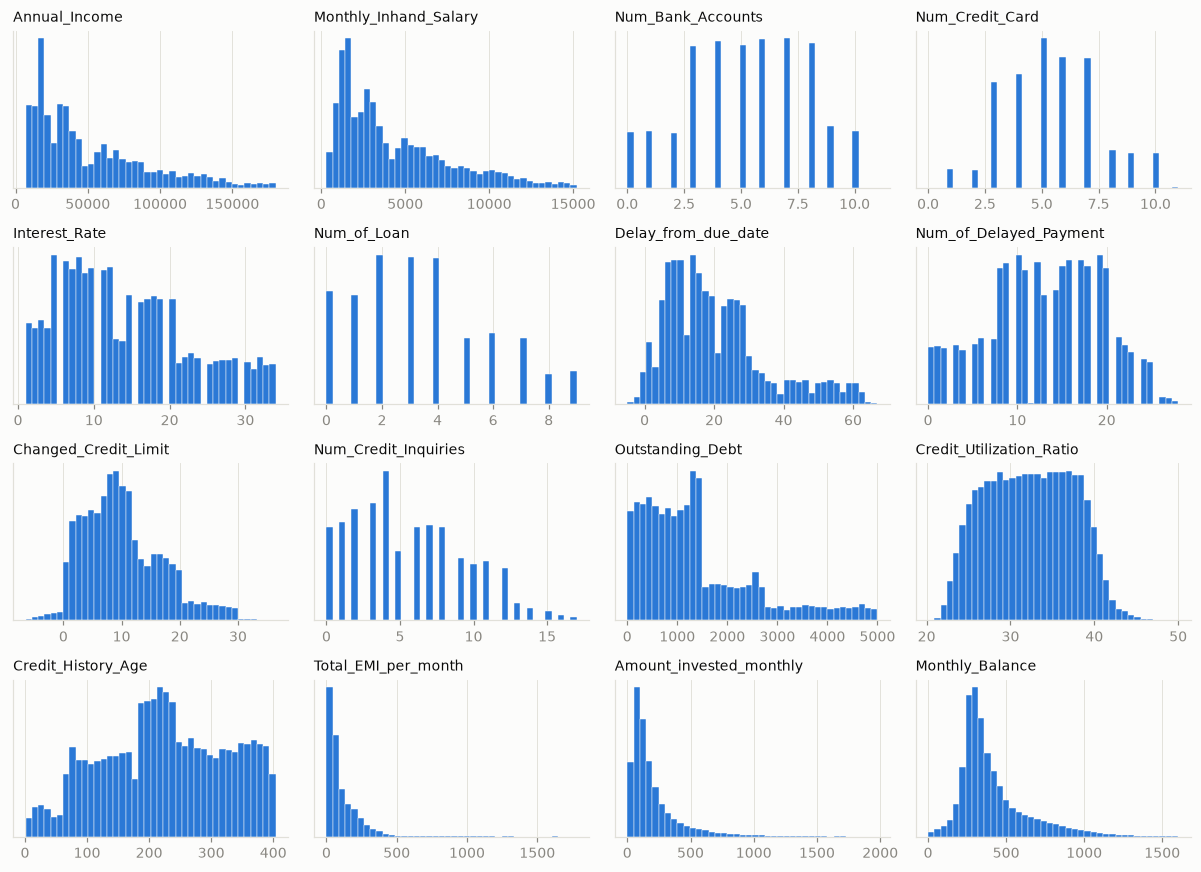

                           skew  outliers (Tukey)  share
Annual_Income             1.107              1472  0.020
Monthly_Inhand_Salary     1.106              1525  0.020
Num_Bank_Accounts        -0.167                 0  0.000
Num_Credit_Card           0.225                 0  0.000
Interest_Rate             0.553                 0  0.000
Num_of_Loan               0.491                 0  0.000
Delay_from_due_date       1.010              3994  0.053
Num_of_Delayed_Payment   -0.166                 0  0.000
Changed_Credit_Limit      0.696              1166  0.016
Num_Credit_Inquiries      0.483                 0  0.000
Outstanding_Debt          1.285              4944  0.066
Credit_Utilization_Ratio  0.028                 4  0.000
Credit_History_Age       -0.119                 0  0.000
Total_EMI_per_month       3.828              3833  0.051
Amount_invested_monthly   2.571              6162  0.082
Monthly_Balance           1.553              5640  0.075


In [8]:
fig, axes = plt.subplots(4, 4, figsize=(11, 8))
for ax, c in zip(axes.flat, NUMERIC):
    ax.hist(train[c].dropna(), bins=40, color=BLUE, edgecolor=SURFACE, linewidth=0.3)
    ax.set_title(c, fontsize=9); ax.set_yticks([]); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

q1, q3 = train[NUMERIC].quantile(.25), train[NUMERIC].quantile(.75)
iqr = q3 - q1
n_out = ((train[NUMERIC] < q1 - 1.5 * iqr) | (train[NUMERIC] > q3 + 1.5 * iqr)).sum()
print(pd.DataFrame({"skew": train[NUMERIC].skew(), "outliers (Tukey)": n_out, "share": n_out / len(train)}).round(3).to_string())

The money columns are right-skewed (`Total_EMI_per_month` skew 3.8, `Amount_invested_monthly` 2.6, `Monthly_Balance` 1.6, `Outstanding_Debt` 1.3, `Annual_Income` and `Monthly_Inhand_Salary` 1.1) and have 2% to 8% of their rows outside the Tukey fences (`Annual_Income` and `Monthly_Inhand_Salary` 2.0%, `Total_EMI_per_month` 5.1%, `Outstanding_Debt` 6.6%, `Monthly_Balance` 7.5%, `Amount_invested_monthly` 8.2%), as does `Delay_from_due_date` (5.3%). These are a heavy tail of real values, not corruption (corrupted values were handled by the cleaning rules), so nothing is removed; a log transform is a candidate for linear models. The count columns, `Interest_Rate` and `Credit_History_Age` have no outliers, and the counts and the interest rate show a discrete, stepped shape.

## 5. Categorical features and the default rate

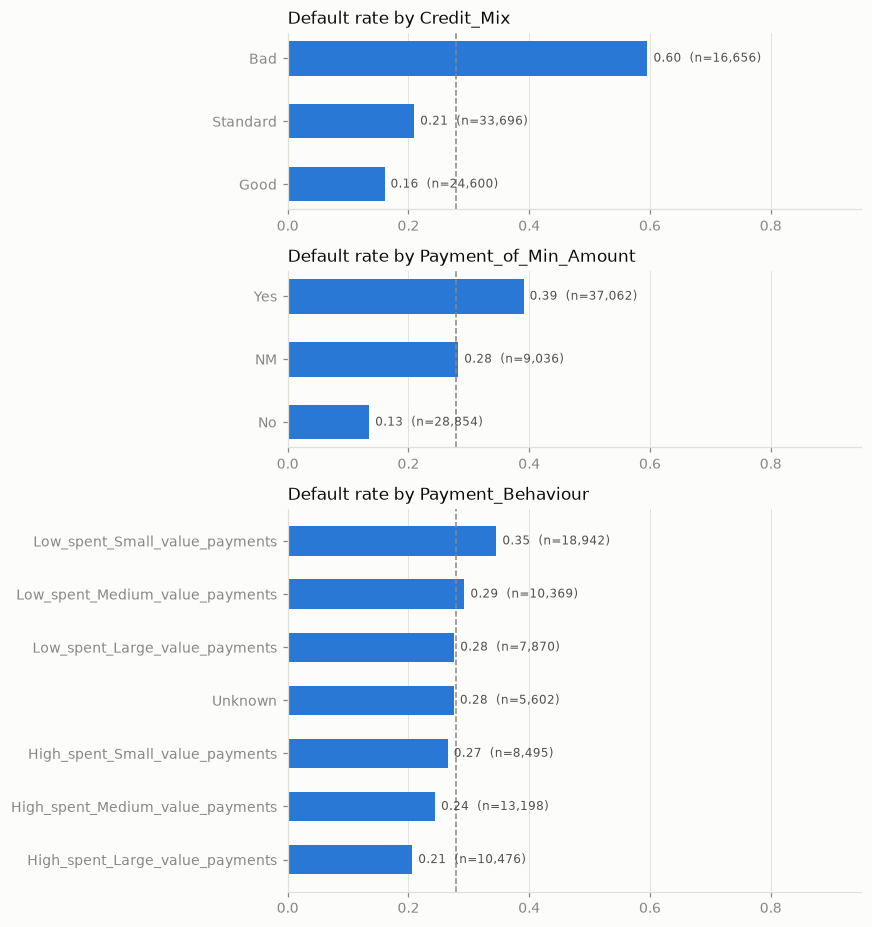

In [9]:
fig, axes = plt.subplots(3, 1, figsize=(8, 8.5), gridspec_kw={"height_ratios": [3, 3, 6.5]})
for ax, c in zip(axes, ["Credit_Mix", "Payment_of_Min_Amount", "Payment_Behaviour"]):
    t = train.groupby(c)["default_risk"].agg(["mean", "size"]).sort_values("mean")
    ax.barh(t.index, t["mean"], color=BLUE, height=0.55)
    for i, (m, n) in enumerate(zip(t["mean"], t["size"])):
        ax.text(m + 0.01, i, f"{m:.2f}  (n={n:,})", va="center", color=INK2, fontsize=8)
    ax.axvline(overall, color=MUTED, ls="--", lw=1)
    ax.set(title=f"Default rate by {c}", xlim=(0, 0.95)); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

`Credit_Mix` is the strongest categorical feature: the default rate is 0.60 for `Bad` against 0.21 for `Standard` and 0.16 for `Good`. `Payment_of_Min_Amount` separates as well: 0.39 for `Yes` (only the minimum amount was paid) against 0.13 for `No`, and `NM` sits at 0.28, close to the overall rate. `Payment_Behaviour` is weaker (0.21 to 0.35), and its `Unknown` category (the placeholder rows) has the overall rate of 0.28, so here too the missing rows carry no signal.

## 6. Associations between variables

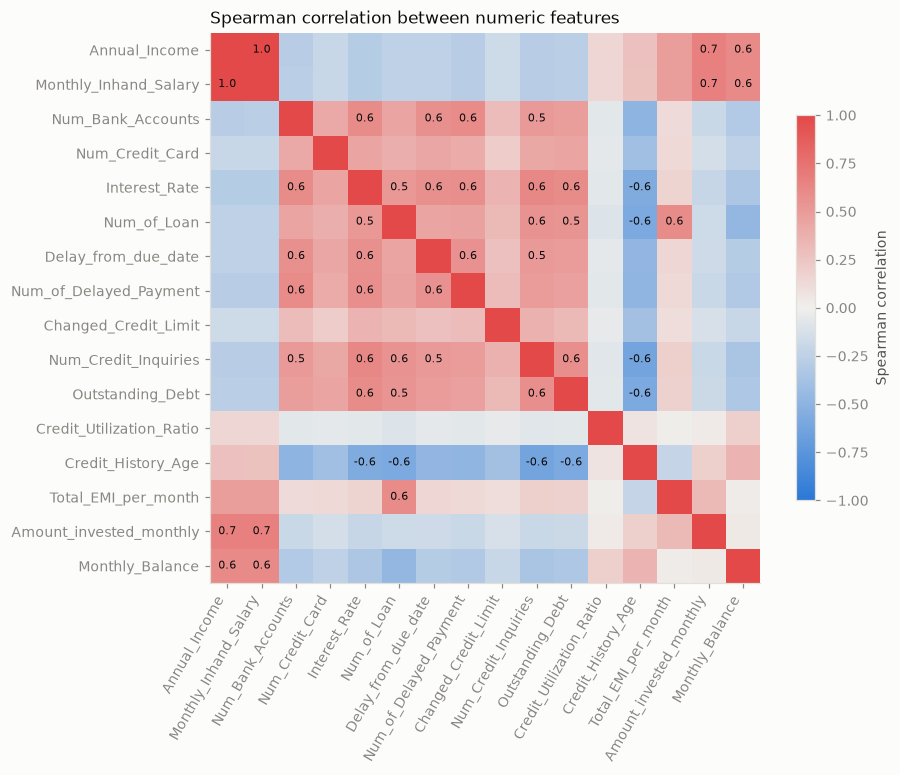

Pairs with |rho| > 0.6:
Annual_Income          Monthly_Inhand_Salary      0.99
Monthly_Inhand_Salary  Amount_invested_monthly    0.66
Annual_Income          Amount_invested_monthly    0.66
Num_Credit_Inquiries   Credit_History_Age        -0.62
Interest_Rate          Num_Credit_Inquiries       0.62
Monthly_Inhand_Salary  Monthly_Balance            0.61
Annual_Income          Monthly_Balance            0.60


In [10]:
corr = train[NUMERIC].corr(method="spearman")
fig, ax = plt.subplots(figsize=(8.5, 7))
im = ax.imshow(corr, cmap=DIVERGING, vmin=-1, vmax=1)
ax.set_xticks(range(len(NUMERIC)), NUMERIC, rotation=60, ha="right"); ax.set_yticks(range(len(NUMERIC)), NUMERIC)
ax.grid(False)
for i in range(len(NUMERIC)):
    for j in range(len(NUMERIC)):
        if i != j and abs(corr.iloc[i, j]) >= 0.5:
            ax.text(j, i, f"{corr.iloc[i, j]:.1f}", ha="center", va="center", fontsize=7, color=INK)
fig.colorbar(im, ax=ax, shrink=0.7).set_label("Spearman correlation", color=INK2)
ax.set_title("Spearman correlation between numeric features")
plt.tight_layout(); plt.show()

pairs = corr.where(np.triu(np.ones(corr.shape, bool), k=1)).stack().rename("rho")
print("Pairs with |rho| > 0.6:")
print(pairs[pairs.abs() > 0.6].sort_values(key=abs, ascending=False).round(2).to_string())

`Annual_Income` and `Monthly_Inhand_Salary` are almost the same variable (Spearman 0.99), so only one of them should enter a model; `Amount_invested_monthly` and `Monthly_Balance` follow them at about 0.6 to 0.7. A second block of credit-stress features moves together at about 0.5 to 0.6 (`Num_Bank_Accounts`, `Interest_Rate`, `Num_of_Loan`, `Delay_from_due_date`, `Num_of_Delayed_Payment`, `Num_Credit_Inquiries`, `Outstanding_Debt`), and `Credit_History_Age` is negatively related to part of it (about -0.6 with `Interest_Rate`, `Num_of_Loan`, `Num_Credit_Inquiries` and `Outstanding_Debt`).

In [11]:
def cramers_v(x, y):
    t = pd.crosstab(x, y)
    chi2 = chi2_contingency(t, correction=False)[0]
    return np.sqrt(chi2 / (t.values.sum() * (min(t.shape) - 1)))

cols = CATEGORICAL + ["Month", "Credit_Score"]
print(pd.DataFrame([[cramers_v(train[a], train[b]) for b in cols] for a in cols], index=cols, columns=cols).round(2).to_string())

                       Occupation  Credit_Mix  Payment_of_Min_Amount  Payment_Behaviour  Month  Credit_Score
Occupation                   1.00        0.04                   0.02               0.01   0.00          0.03
Credit_Mix                   0.04        1.00                   0.54               0.08   0.00          0.45
Payment_of_Min_Amount        0.02        0.54                   1.00               0.07   0.01          0.31
Payment_Behaviour            0.01        0.08                   0.07               1.00   0.01          0.08
Month                        0.00        0.00                   0.01               0.01   1.00          0.03
Credit_Score                 0.03        0.45                   0.31               0.08   0.03          1.00


Among the categorical features, `Credit_Mix` and `Payment_of_Min_Amount` are strongly associated (Cramer's V 0.54), while `Occupation`, `Payment_Behaviour` and `Month` are nearly independent of the others (V of 0.08 or less).

## 7. Features against the target

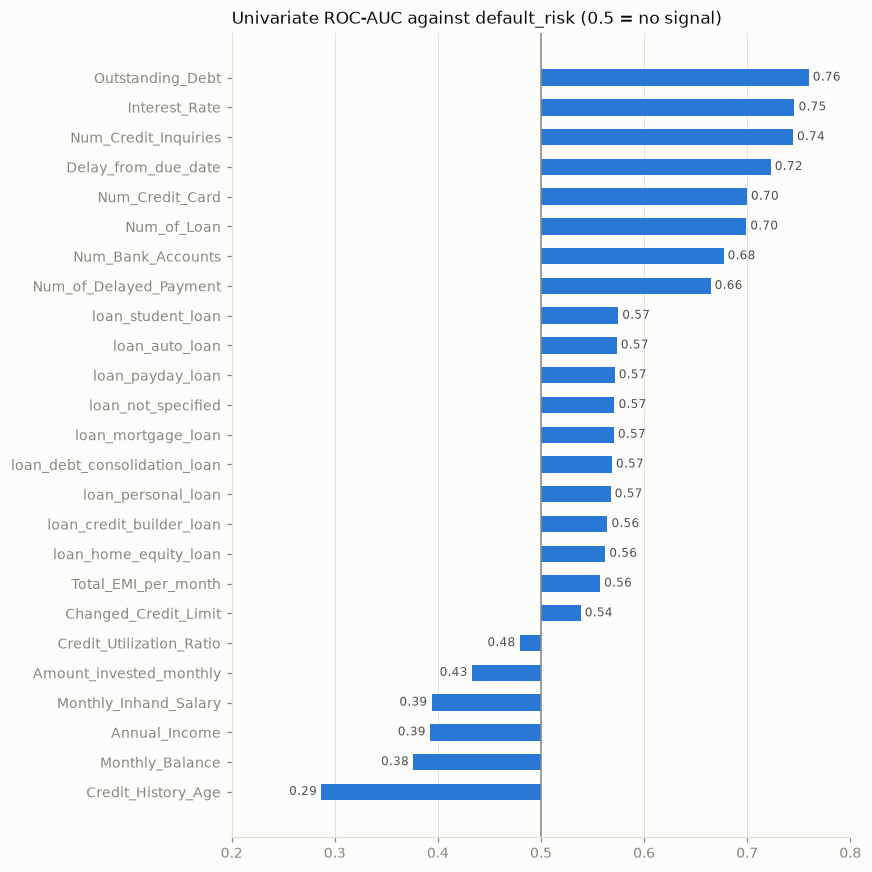

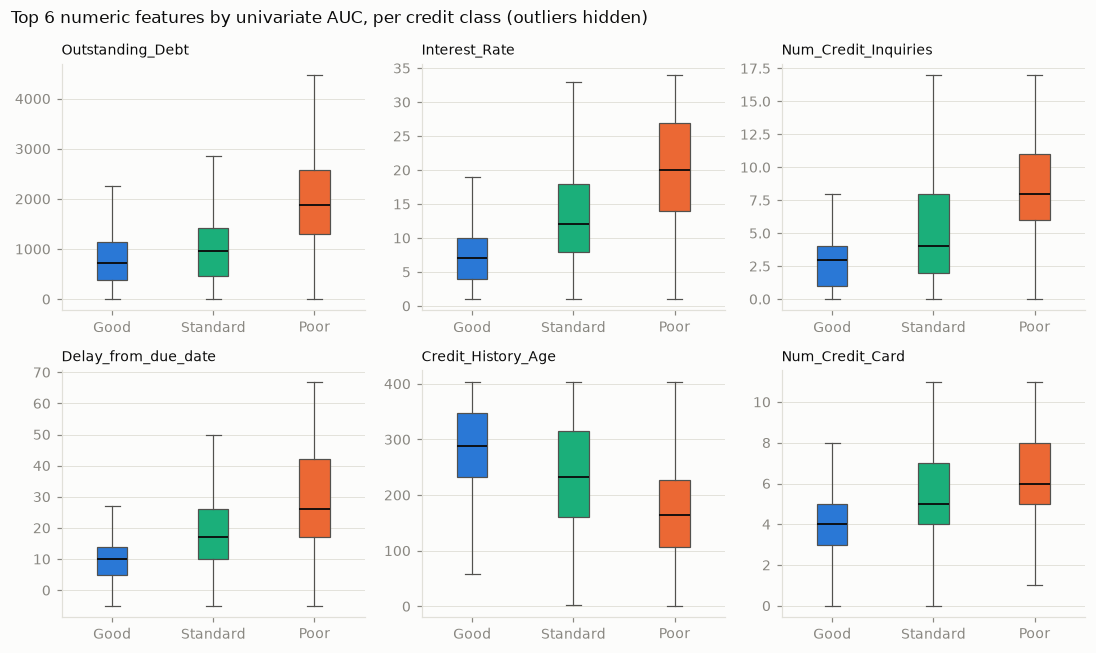

Cramer's V against default_risk: {'Occupation': 0.029, 'Credit_Mix': 0.38, 'Payment_of_Min_Amount': 0.265, 'Payment_Behaviour': 0.103}
Leakage screen (AUC > 0.85 or < 0.15, Cramer's V > 0.5): nothing flagged
Outstanding_Debt                0.760
Interest_Rate                   0.746
Num_Credit_Inquiries            0.744
Delay_from_due_date             0.723
Num_Credit_Card                 0.700
Num_of_Loan                     0.699
Num_Bank_Accounts               0.677
Num_of_Delayed_Payment          0.665
loan_student_loan               0.575
loan_auto_loan                  0.573
loan_not_specified              0.571
loan_payday_loan                0.571
loan_mortgage_loan              0.571
loan_debt_consolidation_loan    0.569
loan_personal_loan              0.567
loan_credit_builder_loan        0.564
loan_home_equity_loan           0.562
Total_EMI_per_month             0.557
Changed_Credit_Limit            0.539
Credit_Utilization_Ratio        0.479
Amount_invested_monthly         

In [12]:
FEATURES = NUMERIC + LOAN_COLUMNS
auc = pd.Series({c: roc_auc_score(train["default_risk"], train[c]) for c in FEATURES}).sort_values()

fig, ax = plt.subplots(figsize=(8, 8))
ax.barh(auc.index, auc.values - 0.5, left=0.5, color=BLUE, height=0.55)
for i, v in enumerate(auc.values):
    ax.text(v + (0.004 if v >= 0.5 else -0.004), i, f"{v:.2f}", va="center", ha="left" if v >= 0.5 else "right", color=INK2, fontsize=8)
ax.axvline(0.5, color=MUTED, lw=1)
ax.set(xlim=(0.2, 0.8), title="Univariate ROC-AUC against default_risk (0.5 = no signal)"); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

top = (auc - 0.5).abs().sort_values(ascending=False).index[:6]
fig, axes = plt.subplots(2, 3, figsize=(10, 6))
for ax, c in zip(axes.flat, top):
    box = ax.boxplot([train.loc[train["Credit_Score"] == k, c] for k in CLASSES], tick_labels=CLASSES, patch_artist=True,
                     showfliers=False, medianprops={"color": INK, "lw": 1.2}, whiskerprops={"color": INK2, "lw": 0.8},
                     capprops={"color": INK2, "lw": 0.8}, boxprops={"lw": 0.8, "edgecolor": INK2})
    for patch, k in zip(box["boxes"], CLASSES):
        patch.set_facecolor(CLASS_COLOR[k])
    ax.set_title(c, fontsize=9); ax.grid(axis="x", visible=False)
plt.suptitle("Top 6 numeric features by univariate AUC, per credit class (outliers hidden)", x=0.01, ha="left", fontsize=11)
plt.tight_layout(); plt.show()

v = pd.Series({c: cramers_v(train[c], train["default_risk"]) for c in CATEGORICAL}).round(3)
print("Cramer's V against default_risk:", v.to_dict())
flagged = auc[(auc > 0.85) | (auc < 0.15)].index.tolist() + v[v > 0.5].index.tolist()
print("Leakage screen (AUC > 0.85 or < 0.15, Cramer's V > 0.5):", flagged or "nothing flagged")
print(auc.round(3).sort_values(ascending=False).to_string())

Univariate ROC-AUC is highest for `Outstanding_Debt` (0.76), `Interest_Rate` (0.75), `Num_Credit_Inquiries` (0.74), `Delay_from_due_date` (0.72), `Num_Credit_Card` and `Num_of_Loan` (0.70). `Credit_History_Age` is the strongest in the other direction (0.29, i.e. 0.71 when inverted), followed by `Monthly_Balance`, `Annual_Income` and `Monthly_Inhand_Salary` (0.38 to 0.39). The individual loan types (0.56 to 0.58) carry little beyond `Num_of_Loan`, and `Credit_Utilization_Ratio` (0.48), `Total_EMI_per_month` (0.56) and `Changed_Credit_Limit` (0.54) show almost no signal on their own. No feature trips the leakage screen (AUC above 0.85 or below 0.15, Cramer's V above 0.5); the strongest categorical feature, `Credit_Mix` (V 0.38 against `default_risk`), stays under watch because it is strongly associated with `Payment_of_Min_Amount`. These are single-feature results on repeated customer rows and do not show how the features work together.

## 8. Can the other features recover age?

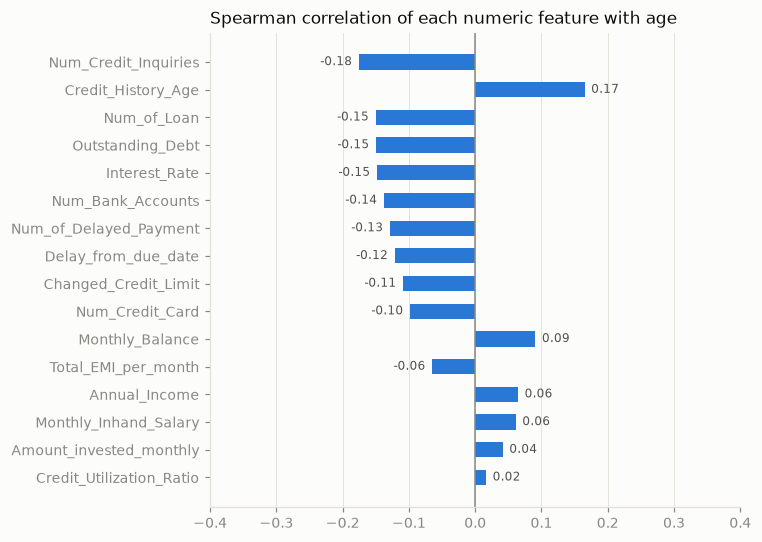

AUC for predicting age 46+ from the other features: 0.742 (folds: [0.74  0.751 0.759 0.726 0.732])


Largest drops in AUC when a feature is shuffled (last fold):
Credit_History_Age      0.045
Outstanding_Debt        0.029
Num_Credit_Inquiries    0.016
Num_of_Loan             0.008
Total_EMI_per_month     0.005


In [13]:
age_by_row = train.groupby("Customer_ID")["Age"].transform("median")
rho_age = pd.Series({c: spearmanr(train[c], age_by_row)[0] for c in NUMERIC}).sort_values(key=abs)

fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(rho_age.index, rho_age.values, color=BLUE, height=0.55)
for i, v in enumerate(rho_age.values):
    ax.text(v + (0.01 if v >= 0 else -0.01), i, f"{v:.2f}", va="center", ha="left" if v >= 0 else "right", color=INK2, fontsize=8)
ax.axvline(0, color=MUTED, lw=1)
ax.set(xlim=(-0.4, 0.4), title="Spearman correlation of each numeric feature with age"); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

X = train[NUMERIC + CATEGORICAL].copy()
for c in X.select_dtypes(exclude="number"):
    X[c] = X[c].astype("category")
y = (train["age_group"] == "46+").astype(int)

scores = []
for tr, te in GroupKFold(5).split(X, y, groups=train["Customer_ID"]):
    model = HistGradientBoostingClassifier(categorical_features="from_dtype", random_state=0).fit(X.iloc[tr], y.iloc[tr])
    scores.append(roc_auc_score(y.iloc[te], model.predict_proba(X.iloc[te])[:, 1]))
print(f"AUC for predicting age 46+ from the other features: {np.mean(scores):.3f} (folds: {np.round(scores, 3)})")

imp = permutation_importance(model, X.iloc[te], y.iloc[te], scoring="roc_auc", n_repeats=3, random_state=0)
print("Largest drops in AUC when a feature is shuffled (last fold):")
print(pd.Series(imp.importances_mean, index=X.columns).sort_values(ascending=False).head(5).round(3).to_string())

No single feature is a strong proxy for age (largest absolute Spearman correlations: `Num_Credit_Inquiries` -0.18 and `Credit_History_Age` 0.17), but together the other features predict whether a customer is 46+ with an AUC of 0.74 (five folds grouped by customer, 0.73 to 0.76). The features carrying the most age information (permutation importance on the last fold) are `Credit_History_Age` (AUC drop of 0.045 when shuffled), `Outstanding_Debt` (0.029) and `Num_Credit_Inquiries` (0.016), which are also among the strongest default predictors. Leaving `Age` out of the model therefore does not remove age from it, and the comparison of a model with and without `Age` planned in the README stays necessary.

## 9. What the API sees: missing values after layer 1 only

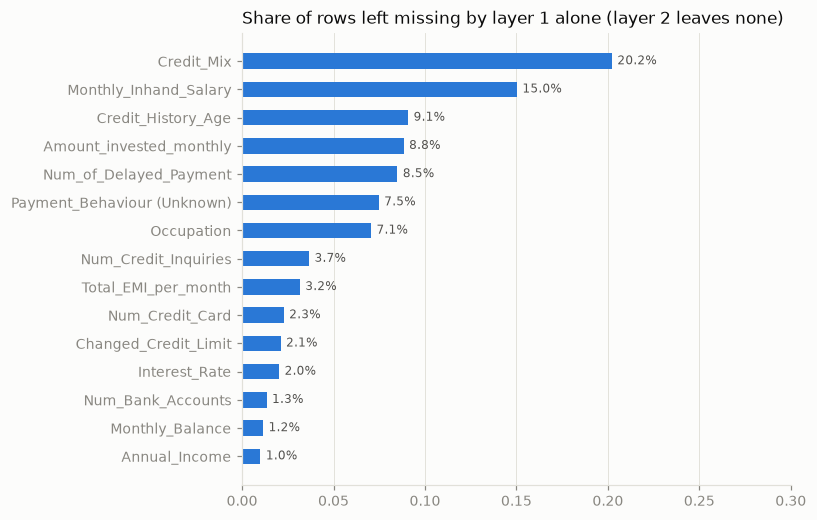

Credit_Mix                     20.2
Monthly_Inhand_Salary          15.0
Credit_History_Age              9.1
Amount_invested_monthly         8.8
Num_of_Delayed_Payment          8.5
Payment_Behaviour (Unknown)     7.5
Occupation                      7.1
Num_Credit_Inquiries            3.7
Total_EMI_per_month             3.2
Num_Credit_Card                 2.3
Changed_Credit_Limit            2.1
Interest_Rate                   2.0
Num_Bank_Accounts               1.3
Monthly_Balance                 1.2
Annual_Income                   1.0


In [14]:
l1 = clean_rows(train_raw)
cols = NUMERIC + ["Occupation", "Credit_Mix"]
missing = l1[cols].isna().mean()
missing["Payment_Behaviour (Unknown)"] = (l1["Payment_Behaviour"] == "Unknown").mean()
missing = missing[missing > 0].sort_values()

fig, ax = plt.subplots(figsize=(7.5, 4.8))
ax.barh(missing.index, missing.values, color=BLUE, height=0.55)
for i, v in enumerate(missing.values):
    ax.text(v + 0.003, i, f"{v:.1%}", va="center", color=INK2, fontsize=8)
ax.set(title="Share of rows left missing by layer 1 alone (layer 2 leaves none)", xlim=(0, 0.3)); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()
print((missing * 100).round(1).sort_values(ascending=False).to_string())

With layer 1 alone, which is all the API can do for a single record, `Credit_Mix` is missing in 20.2% of the rows, `Monthly_Inhand_Salary` in 15.0%, `Credit_History_Age` in 9.1%, `Amount_invested_monthly` in 8.8% and `Num_of_Delayed_Payment` in 8.5%, and `Payment_Behaviour` is `Unknown` in 7.5%. Several of these are among the strongest predictors (`Credit_Mix`, `Credit_History_Age`), so the gap between a held-out set cleaned with layer 2 and the API is likely to be largest there. The README commits to measuring it by scoring the held-out set with layer 1 only.

## Findings and next steps

- The split keeps the default rate (0.279) and the age mix equal in the training and held-out parts.
- Default rate by age is flat at 0.30-0.31 up to 45 and 0.126 for 46+; occupation shows no clear difference.
- The strongest single signals are `Outstanding_Debt`, `Interest_Rate`, `Num_Credit_Inquiries`, `Delay_from_due_date` and (inverted) `Credit_History_Age`, plus `Credit_Mix` and `Payment_of_Min_Amount` among the categoricals.
- `Annual_Income` and `Monthly_Inhand_Salary` are redundant (Spearman 0.99); the money columns are right-skewed.
- Age is partly recoverable from the other features (AUC 0.74), through some of the strongest default predictors.
- Layer 1 alone leaves `Credit_Mix` missing in 20.2% of the rows, so the gap with the API is most likely to show there.

Ideas to test when building features (not validated here): ratios such as `Outstanding_Debt / Annual_Income`, `Total_EMI_per_month / Monthly_Inhand_Salary` and `Amount_invested_monthly / Monthly_Inhand_Salary`; a log transform of the skewed money columns; only one of `Annual_Income` and `Monthly_Inhand_Salary`. Still open: whether `Month` is a feature.